---
title: "Домашнее задание 3: dN/dS анализ"
execute:
  enabled: false
---

# **Сравнительная геномика** | Семинар + ДЗ

**Дисклеймер** \
Предполагается, что вы ознакомились с лекцией перед тем, как открыть этот ноутбук. Здесь не будет подробных объяснений теоретических основ сравнительной геномики, поэтому если они вам не знакомы, то первым делом изучите лекционный материал

**ПОЛИТИКА В ОТНОШЕНИИ ГПТ** \
Я не психопат (во всяком случае не настолько), чтобы с серьезным лицом запрещать вам использовать ллмки. Однако, если вы делаете это крайне безответственно, то будут санкции в виде снижения оценки. Например, однажды в Сколтехе студентка написала функцию определения $R^2$ в ячейке под той, в которой показано, как вызвать подсчет этой метрики в phylokrr одной строкой. Лицо мое представили

**ЕЩЕ ОДНО ПРЕДУПРЕЖДЕНИЕ! Не запускайте бездумно все ячейки подряд, как бы сильно не хотелось. Спамить шифт+энтер здесь не получится...**

## Настройка конда среды и установка нужных библиотек

выполняю все локально

In [ ]:
#conda create -y -n hyphy -c conda-forge -c bioconda python hyphy=2.5.85
#conda activate hyphy
#mkdir -p hw3_mat
#cd hw3_mat
#git clone https://github.com/Malaevleo/cba_comp_age_hw.git

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import subprocess
import os
import json
warnings.filterwarnings('ignore')

## Вступление

В этом ноутбуке мы сфокусируемся на отряде *Chiroptera* (Рукокрылые). Многие его представители живут удивительно долго. Например, *Myotis brandtii* (Ночница Брандта) может жить 40+ лет при весе всего в 7 грамм. Очень интересно узнать, какие генетические адаптации могут стоять за таким биологическим феноменом

Добавим значения LQ из датабазы AnnAge и разделим летучих мышей на 3 категории в зависимости от LQ.

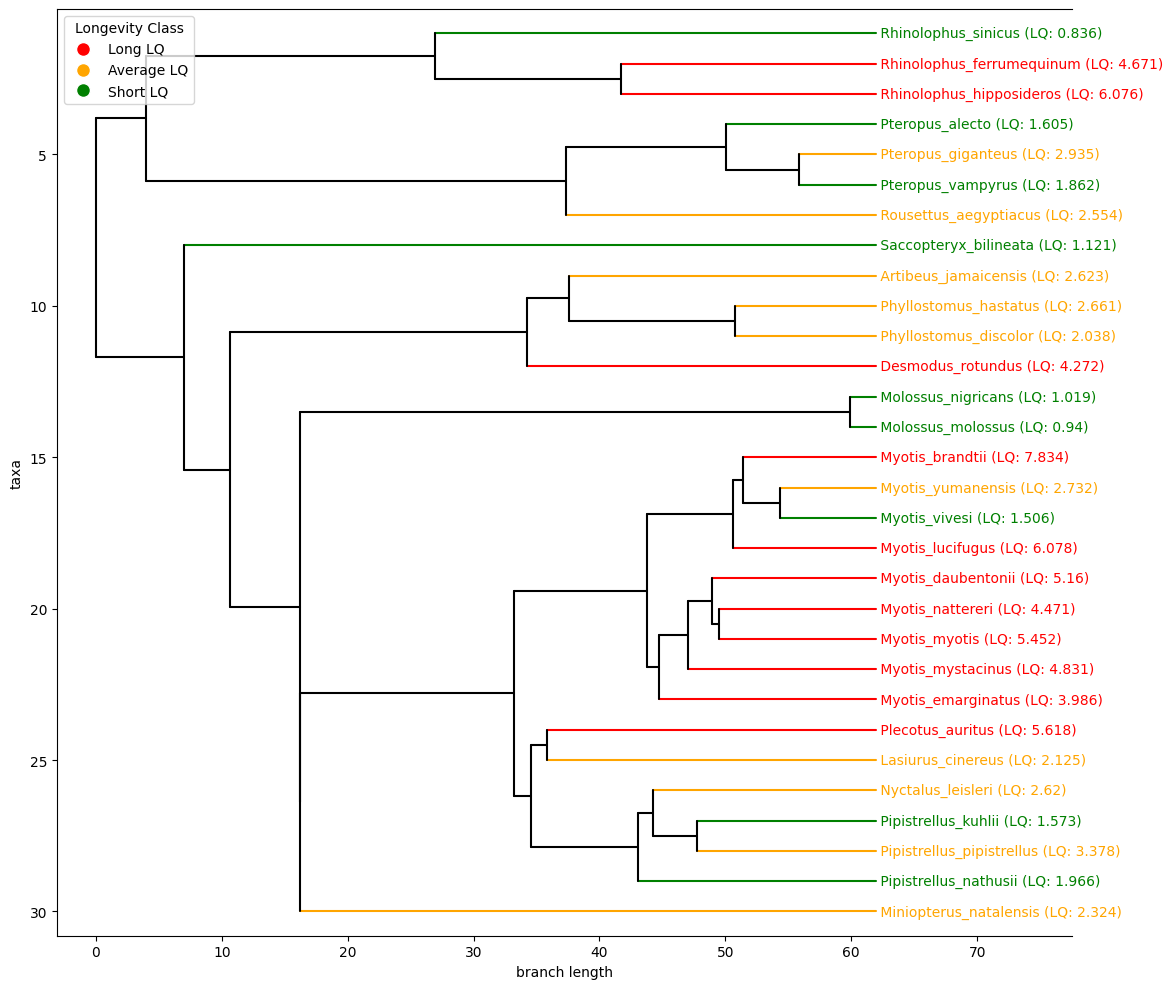

Всего у нас 30 видов, что, конечно, не так уж и много, но вполне неплохо для одной клады. Особенно интересно разнообразие по продолжительности жизни, нормализованной по массе.

Проведем анализ, взяв за основу следующий пайплайн:

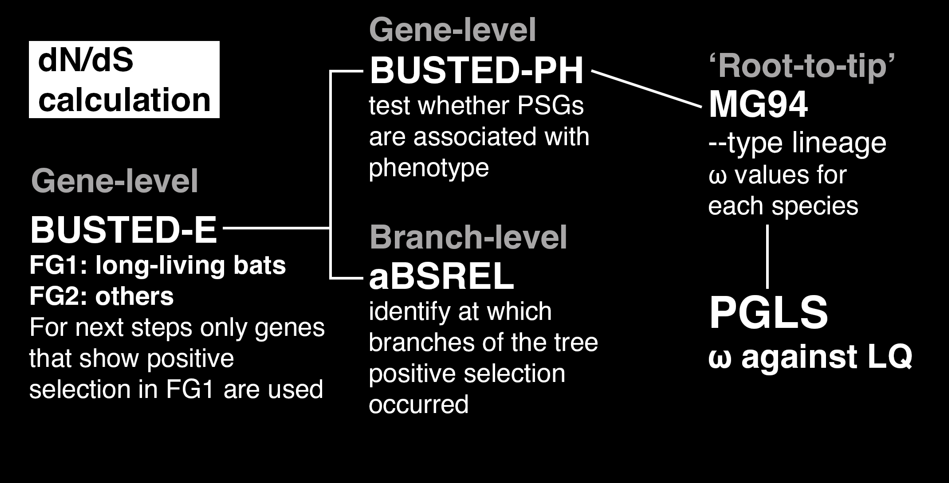

Он включает в себя почти все, что обсуждалось на лекции, а также позволяет оценить отбор на уровне индивидуальных ветвей и оценить ассоциацию dN/dS с любой количественной метрикой (в нашем случае LQ).

## Данные

Для каждого гена у нас есть и MSA, и дерево.

**MMP25:** \
mmp25_aln.fasta -> MSA \
mmp25_tree.nwk -> phylogenetic tree \
Аналогично для других генов (CLEC14A, POLG).

MMP25 - матрисомная металлпротеаза, являющаяся важным компонентом внеклеточного матрикса.

## dN/dS

### BUSTED

Создадим функцию, запускающую BUSTED-E

In [ ]:
hyphy busted \
  --alignment cba_comp_age_hw/mmp25_aln.fasta \
  --tree cba_comp_age_hw/mmp25_tree.nwk \
  --branches Foreground \
  --error-sink Yes \
  --output mmp25_res.json > mmp25_log.txt 2>&1

Наша функция `run_busted` использует 3 аргумента:

1.   `align` MSA
2.   `tree` дерево
3. `branches` какая группа ветвей тестируется на положительный отбор. Модель с 3 $\omega$ классами фитится на эти ветви

В среднем на прогон уходит от 5 до 40 минут в случае большого количества видов

Давайте посмотрим на результаты. Они сохранены в json файле и еще в txt с логом.

Можем визуализировать json:

In [2]:
def check_busted_results(path=None, constrained = False):
  with open(path) as f:
      data = json.load(f)


  lrt = data["test results"]["LRT"]
  p_value = data["test results"]["p-value"]
  logL_unconstrained = data["fits"]["Unconstrained model"]["Log Likelihood"]
  if constrained:
    logL_constrained = data["fits"]["Constrained model"]["Log Likelihood"]

  print(f"LRT statistic: {lrt:.4f}")
  print(f"P-value: {p_value:.4g}")
  print(f"Unconstrained logL: {logL_unconstrained:.4f}")
  if constrained:
    print(f"Constrained logL: {logL_constrained:.4f}")

check_busted_results("../hw3_mat/mmp25_res.json", True)

LRT statistic: 6.2130
P-value: 0.02238
Unconstrained logL: -7931.3736
Constrained logL: -7934.4801


Как мы видим, этот ген претерпевает положительный отбор. Для более детального анализа перейдем к следующим стадиям пайплайна.

Можно посмотреть, есть ли отбор на фоновых ветвях.

In [ ]:
hyphy busted \
  --alignment cba_comp_age_hw/mmp25_aln.fasta \
  --tree cba_comp_age_hw/mmp25_tree.nwk \
  --branches Background \
  --error-sink Yes \
  --output background_mmp25_res.json > background_mmp25_log.txt 2>&1

In [11]:
check_busted_results(path="../hw3_mat/background_mmp25_res.json")

LRT statistic: 0.0000
P-value: 0.5
Unconstrained logL: -7935.4012


в результатах нет поля constrained и 

LRT (насколько сильно ограничение на омегу ухудшило фит) =  2 × (logL_unconstrained − logL_constrained) = 0 , 


значит обе модели constrained и unconstrained дали абсолютно одинаковый фит и отбора нет!

**Давайте изучим, на каких конкретно ветвях дерева мог возникнуть положительный отбор**

### aBSREL

В этом методе мы не указываем, какие ветви хотим смотреть, потому что он должен анализировать все.

In [ ]:
hyphy absrel \
    --alignment cba_comp_age_hw/mmp25_aln.fasta \
    --tree cba_comp_age_hw/mmp25_tree.nwk \
    --output mmp25_absrel_res.json > mmp25_absrel_log.txt 2>&1

Изучим результаты:

In [12]:
with open("../hw3_mat/mmp25_absrel_res.json") as f:
    data = json.load(f)


pos_test_res = data["test results"]["positive test results"]


print(f"Positive test results: {pos_test_res:f}")


Positive test results: 2.000000


Ветви с положительном отбором нашлись. Давайте посмотрим, какие это мыши:

In [14]:
def check_absrel_results(path=None):
  with open(path) as f:
      data = json.load(f)


  pos_test_res = data["test results"]["positive test results"]


  print(f"Positive test results: {pos_test_res:f}")

  branches = data["branch attributes"]["0"]

  print("Branches under episodic positive selection:\n")

  for bname, attrs in branches.items():
      pval = attrs.get("Corrected P-value", 1)
      if pval < 0.05:
          LRT = attrs.get("LRT", None)
          rate_dist = attrs.get("Rate Distributions", [])
          omega, prop = None, None
          if len(rate_dist) > 1:  # 2+ classes → second one is usually ω>1
              omega, prop = rate_dist[-1]
          elif rate_dist:         # only one class (impossible situation basically)
              omega, prop = rate_dist[0]

          print(f"{bname:25s}  p={pval:.2e}  LRT={LRT:.2f}  ω={omega:.2f}  prop={prop:.2%}")

check_absrel_results(path="../hw3_mat/mmp25_absrel_res.json")

Positive test results: 2.000000
Branches under episodic positive selection:

mbXP_014392669_1           p=0.00e+00  LRT=78.71  ω=244.99  prop=4.08%
mlXP_006090523_1           p=9.97e-03  LRT=15.03  ω=2028.69  prop=0.27%


*Myotis brandtii* и *Myotis lucifugus* демонстируют положительный отбор. Это одни из самых долгоживущих летучих мышей в природе, поэтому это весьма закономерно.

## MG94 root-to-tip dN/dS calculation

MG94 с опцией "lineage" используется для расчета dN/dS от корня до вершины (листа) дерева. Корень здесь - общий предок всех рукокрылых. \
Увы, запуск root-to-tip расчета требует неких танцев с бубном, поскольку для этого нужно загружать дополнительный набор скриптов hyphy-analyses и надеяться, что патчи на сам hyphy ничего не сломали.


In [ ]:
# git clone --depth 1 https://github.com/veg/hyphy-analyses.git ~/hyphy-analyses

# ls ~/hyphy-analyses/FitMG94/
# hyphy ~/hyphy-analyses/FitMG94/FitMG94.bf --help

In [ ]:
hyphy ~/hyphy-analyses/FitMG94/FitMG94.bf \
    --alignment cba_comp_age_hw/mmp25_aln.fasta \
    --tree cba_comp_age_hw/mmp25_tree.nwk \
    --type lineage \
    --output mmp25_mg94_res.json > mmp25_mg94_log.txt 2>&1

Создадим csv файл, который потом будем использовать для PGLS

In [16]:
d=json.load(open("../hw3_mat/mmp25_mg94_res.json"))["branch attributes"]["0"]
pd.DataFrame([{"node":k,"lineage_dNdS":v["Lineage dN/dS"]} for k,v in d.items()if"Lineage dN/dS"in v]).to_csv("../hw3_mat/mmp25_dnds.csv",index=False)


In [17]:
df = pd.read_csv("../hw3_mat/mmp25_dnds.csv")
df.head()

,node,lineage_dNdS
0,ajXP_037010567_1,0.158041
1,drXP_024409158_2,0.182529
2,lcg18142_t1,0.194287
3,mag18797_t1,0.222001
4,mbXP_014392669_1,0.262496


Добавим в датафрейм названия видов и LQ, потому что это потребуется для PGLS

In [17]:
REF = {
    'aj': {'Species': 'Artibeus_jamaicensis',      'LQ': 2.6},
    'dr': {'Species': 'Desmodus_rotundus',         'LQ': 4.3},
    'lc': {'Species': 'Lasiurus_cinereus',         'LQ': 2.1},
    'ma': {'Species': 'Myotis_nattereri',          'LQ': 4.5},
    'mb': {'Species': 'Myotis_brandtii',           'LQ': 7.8},
    'md': {'Species': 'Myotis_daubentonii',        'LQ': 5.2},
    'me': {'Species': 'Myotis_emarginatus',        'LQ': 4.0},
    'mi': {'Species': 'Molossus_nigricans',        'LQ': 1.0},
    'ml': {'Species': 'Myotis_lucifugus',          'LQ': 6.0},
    'mm': {'Species': 'Myotis_myotis',             'LQ': 5.5},
    'mn': {'Species': 'Miniopterus_natalensis',    'LQ': 2.3},
    'mo': {'Species': 'Molossus_molossus',         'LQ': 0.9},
    'ms': {'Species': 'Myotis_mystacinus',         'LQ': 4.8},
    'mv': {'Species': 'Myotis_vivesi',             'LQ': 1.5},
    'my': {'Species': 'Myotis_yumanensis',         'LQ': 2.7},
    'nl': {'Species': 'Nyctalus_leisleri',         'LQ': 2.6},
    'pa': {'Species': 'Pteropus_alecto',           'LQ': 1.6},
    'pd': {'Species': 'Phyllostomus_discolor',     'LQ': 2.0},
    'pg': {'Species': 'Pteropus_giganteus',        'LQ': 2.9},
    'ph': {'Species': 'Phyllostomus_hastatus',     'LQ': 2.7},
    'pk': {'Species': 'Pipistrellus_kuhlii',       'LQ': 1.6},
    'pn': {'Species': 'Pipistrellus_nathusii',     'LQ': 2.0},
    'pp': {'Species': 'Pipistrellus_pipistrellus', 'LQ': 3.4},
    'pu': {'Species': 'Plecotus_auritus',          'LQ': 5.6},
    'pv': {'Species': 'Pteropus_vampyrus',         'LQ': 1.9},
    'ra': {'Species': 'Rousettus_aegyptiacus',     'LQ': 2.6},
    'rf': {'Species': 'Rhinolophus_ferrumequinum', 'LQ': 4.7},
    'rh': {'Species': 'Rhinolophus_hipposideros',  'LQ': 6.1},
    'rs': {'Species': 'Rhinolophus_sinicus',       'LQ': 0.8},
    'sb': {'Species': 'Saccopteryx_bilineata',     'LQ': 1.1},
}


In [19]:
code = df["node"].str[:2].str.lower()
df["Species"] = code.map(lambda c: REF.get(c, {}).get("Species"))
df["LQ"] = code.map(lambda c: REF.get(c, {}).get("LQ"))

df.to_csv("../hw3_mat/mmp25_dnds_LQ.csv", index=False)
print(df.head())


               node  lineage_dNdS               Species   LQ
0  ajXP_037010567_1      0.158041  Artibeus_jamaicensis  2.6
1  drXP_024409158_2      0.182529     Desmodus_rotundus  4.3
2       lcg18142_t1      0.194287     Lasiurus_cinereus  2.1
3       mag18797_t1      0.222001      Myotis_nattereri  4.5
4  mbXP_014392669_1      0.262496       Myotis_brandtii  7.8


Давайте посмотрим, отличаются ли мыши из рода *Myotis* от остальных

group
Myotis    0.228640
Other     0.177421
Name: lineage_dNdS, dtype: float64


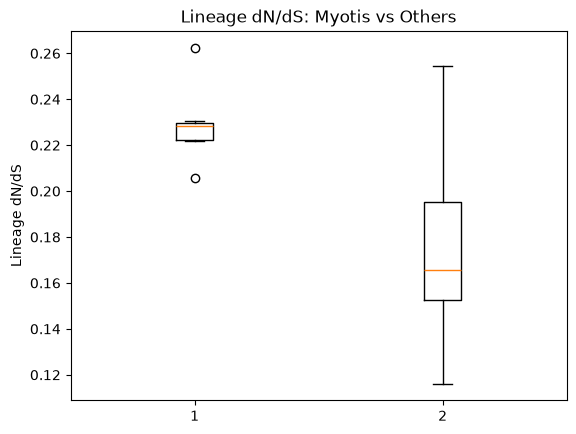

In [21]:
myotis_dict = {"mb", "ml", "md", "mm", "me", "ma", "my"}
df["code"] = df["node"].str[:2].str.lower()
df["group"] = df["code"].isin(myotis_dict).map({True: "Myotis", False: "Other"})

print(df.groupby("group")["lineage_dNdS"].mean())

plt.figure()
plt.boxplot(
    [df.loc[df["group"]=="Myotis","lineage_dNdS"],
     df.loc[df["group"]=="Other","lineage_dNdS"]],
    label=["Myotis","Other"],
    showmeans=False
)
plt.ylabel("Lineage dN/dS")
plt.title("Lineage dN/dS: Myotis vs Others")
plt.show()

## PGLS

К сожалению тут удобнее всего перезапустить среду колаба, чтобы избежать конфликтов при установке пакета phylokrr. Понимаю, что звучит ужасно, но это действительно наиболее быстрый способ продолжить работу. \
**Обязательно предварительно сохраните csv файлы с результатами dN/dS анализа!**

In [ ]:
#conda create -n pgls python=3.11 pandas numpy matplotlib seaborn biopython -c conda-forge
#conda activate pgls

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#python -m pip install phylokrr biopython
from Bio import Phylo
from phylokrr.dataio import read_data
from phylokrr.utils import weight_data
from phylokrr.kernels import KRR
from phylokrr.utils import PGLS
from phylokrr.utils import k_fold_cv_random

In [4]:
df = pd.read_csv("../hw3_mat/mmp25_dnds_LQ.csv")
df.head()

,node,lineage_dNdS,Species,LQ
0,ajXP_037010567_1,0.158041,Artibeus_jamaicensis,2.6
1,drXP_024409158_2,0.182529,Desmodus_rotundus,4.3
2,lcg18142_t1,0.194287,Lasiurus_cinereus,2.1
3,mag18797_t1,0.222001,Myotis_nattereri,4.5
4,mbXP_014392669_1,0.262496,Myotis_brandtii,7.8


Для PGLS в phylokrr нам нужен отдельный датафрейм с независимыми переменными и таргетом, список видов и дерево. Но есть нюанс: внутренние ноды (промежуточные) не должны быть подписаны вообще никак. Почему так сделано? Потому что автор библиотеки - сверхчеловек по Ницше


In [11]:
df_modified = df.drop(["node", "Species"], axis=1)
df_modified.to_csv('../hw3_mat/test_data.csv', index=False, header=False)
df_modified.head()

,lineage_dNdS,LQ
0,0.158041,2.6
1,0.182529,4.3
2,0.194287,2.1
3,0.222001,4.5
4,0.262496,7.8


In [6]:
species_names = df['Species']
species_names.to_csv('../hw3_mat/species.txt', index= False, header=None)
species_names.head()

0    Artibeus_jamaicensis
1       Desmodus_rotundus
2       Lasiurus_cinereus
3        Myotis_nattereri
4         Myotis_brandtii
Name: Species, dtype: str

In [7]:
tree_file = "../hw3_mat/cba_comp_age_hw/pgls_tree.txt"

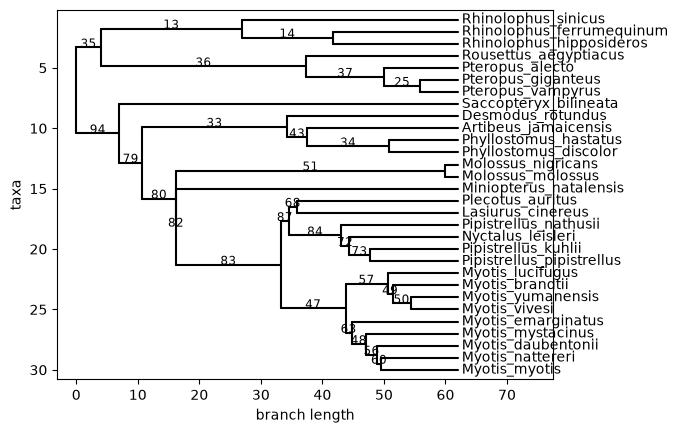

In [8]:
tree = Phylo.read(tree_file, "newick")
tree.ladderize()
Phylo.draw(tree)

Люблю ASCII арт, давайте посмотрим на наше дерево вот так:

In [9]:
Phylo.draw_ascii(tree)

                       ___________________________ Rhinolophus_sinicus
     _________________|
    |                 |           ________________ Rhinolophus_ferrumequinum
    |                 |__________|
  __|                            |________________ Rhinolophus_hipposideros
 |  |
 |  |                          ___________________ Rousettus_aegyptiacus
 |  |_________________________|
 |                            |          _________ Pteropus_alecto
 |                            |_________|
 |                                      |     ____ Pteropus_giganteus
_|                                      |____|
 |                                           |____ Pteropus_vampyrus
 |
 |     ___________________________________________ Saccopteryx_bilineata
 |    |
 |    |                      _____________________ Desmodus_rotundus
 |    |   __________________|
 |____|  |                  |  ___________________ Artibeus_jamaicensis
      |  |                  |_|
      |  |              

phylokrr может "взвешивать" данные. Это необходимо для использования нелинейного ядра. В нашем случае можно обойтись и без этого.


X shape:  (30, 1)
numeric columns:  [0]
categorical columns:  []
30 names from data, 30 from tree, 30 intersect


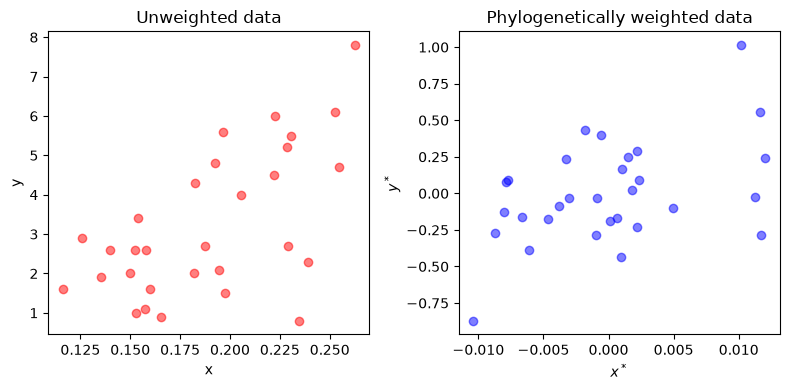

In [12]:
data_file = "../hw3_mat/test_data.csv"


data_file_spps = "../hw3_mat/species.txt"

X_uw_uc, y_uw_uc, vcv = read_data(tree_file, data_file, data_file_spps,
                                  y_col = 1, # таргет
                                  delimiter = ',', verbose = True)

X_w, y_w = weight_data(X_uw_uc, y_uw_uc, vcv, use_sd = False)


np.random.seed(12038)

fig, axs = plt.subplots(1, 2, figsize=(8, 4))
axs[0].scatter(X_uw_uc, y_uw_uc, color = 'red', alpha=0.5, )
axs[0].set_title('Unweighted data')
axs[0].set_xlabel('x')
axs[0].set_ylabel('y')
axs[1].scatter(X_w, y_w, color = 'blue', alpha=0.5, )
axs[1].set_title('Phylogenetically weighted data')
axs[1].set_xlabel('$x^*$')
axs[1].set_ylabel('$y^*$')
plt.tight_layout()

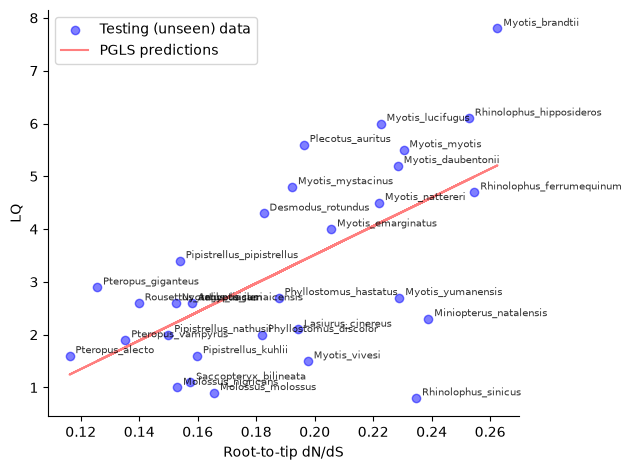

In [15]:

#X_train = X_w
#y_train = y_w
with open(data_file_spps) as f:
    species = [line.strip() for line in f]

X_train = X_uw_uc
y_train = y_uw_uc

X_plot = X_train.ravel()
y_plot = y_train.ravel()

# PGLS
pgls = PGLS(fit_intercept=True)
pgls.fit(X_train, y_train)
y_pred_pgls = pgls.predict(X_train)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.scatter(X_plot, y_plot , color = 'blue' , alpha=0.5, label = 'Testing (unseen) data')
plt.plot(X_plot, y_pred_pgls, color = 'red', alpha=0.5, label = 'PGLS predictions')
dx = 0.002   #оффсет чтоб не было оверлепа
dy = 0.05
for i, sp in enumerate(species):
    plt.text(X_plot[i] + dx, y_plot[i] + dy, sp, fontsize=7, alpha=0.8)
plt.xlabel('Root-to-tip dN/dS')
plt.ylabel('LQ')
plt.legend()
plt.tight_layout()

In [16]:
r2_pgls = pgls.score(X_train, y_train, metric='r2')
rmse = pgls.score(X_train, y_train, metric ='rmse')
print(f"R2 for PGLS: {r2_pgls}")
print(f"RMSE for PGLS: {rmse}")

R2 for PGLS: 0.3715854914386191
RMSE for PGLS: 1.428364277158399


Для одного гена очень интересный результат!\

## Домашнее задание

### **Задание 1**
Проведите аналогичный анализ с генами CLEC14A и POLG. Объясните полученные результаты. Что могло пойти не так в случае с POLG?

*Всегда соблюдайте порядок видов для корректной работы PGLS*

In [ ]:
conda activate hyphy

Для Foreground ветвей:

In [ ]:
for gene in CLEC14A POLG; do
    echo "$gene"
    hyphy busted \
        --alignment "cba_comp_age_hw/${gene}_aln.fasta" \
        --tree "cba_comp_age_hw/${gene}_tree.nwk" \
        --branches Foreground \
        --error-sink Yes \
        --output "${gene}_busted_res.json" > "${gene}_busted_log.txt" 2>&1
done

In [6]:
print('CLEC14A:')
check_busted_results("../hw3_mat/CLEC14A_busted_res.json", True)
print('POLG:')
check_busted_results("../hw3_mat/POLG_busted_res.json", True)

CLEC14A:
LRT statistic: 6.7123
P-value: 0.01743
Unconstrained logL: -4799.3269
Constrained logL: -4802.6831
POLG:
LRT statistic: 6.5292
P-value: 0.01911
Unconstrained logL: -10933.1649
Constrained logL: -10936.4295


это значимые результаты для положительного отбора на генном уровне

Для Background ветвей:

In [ ]:
for gene in CLEC14A POLG; do
    echo "$gene"
    hyphy busted \
        --alignment "cba_comp_age_hw/${gene}_aln.fasta" \
        --tree "cba_comp_age_hw/${gene}_tree.nwk" \
        --branches Background \
        --error-sink Yes \
        --output "background_${gene}_busted_res.json" > "background_${gene}_busted_log.txt" 2>&1
done

In [8]:
print('CLEC14A:')
check_busted_results("../hw3_mat/background_CLEC14A_busted_res.json", True)
print('POLG:')
check_busted_results("../hw3_mat/background_POLG_busted_res.json", False)

CLEC14A:
LRT statistic: 0.1955
P-value: 0.4534
Unconstrained logL: -4807.3917
Constrained logL: -4807.4894
POLG:
LRT statistic: 0.0000
P-value: 0.5
Unconstrained logL: -10954.0468


отбора на фоновых ветвях нет

absrel:

In [ ]:
for gene in CLEC14A POLG; do
    echo "$gene"
    hyphy absrel \
    --alignment cba_comp_age_hw/${gene}_aln.fasta \
    --tree cba_comp_age_hw/${gene}_tree.nwk \
    --output ${gene}_absrel_res.json > ${gene}_absrel_log.txt 2>&1
done    

In [13]:
for gene in ["CLEC14A", "POLG"]:
    with open(f"../hw3_mat/{gene}_absrel_res.json") as f:
        data = json.load(f)
    pos_test_res = data["test results"]["positive test results"]
    print(f"{gene} Positive test results: {pos_test_res:f}")


CLEC14A Positive test results: 1.000000
POLG Positive test results: 1.000000


In [15]:
print('CLEC14A:')
check_absrel_results("../hw3_mat/CLEC14A_absrel_res.json")
print('POLG:')
check_absrel_results("../hw3_mat/POLG_absrel_res.json")

CLEC14A:
Positive test results: 1.000000
Branches under episodic positive selection:

mlXP_006085874_2           p=0.00e+00  LRT=76.46  ω=347.03  prop=5.63%
POLG:
Positive test results: 1.000000
Branches under episodic positive selection:

mbXP_014389040_1           p=0.00e+00  LRT=224.71  ω=4930.16  prop=8.29%


это те же мышки, что и в анализе гена mmp25!

MG94 root-to-tip dN/dS calculation:

In [ ]:
for gene in CLEC14A POLG; do
    hyphy ~/hyphy-analyses/FitMG94/FitMG94.bf \
        --alignment cba_comp_age_hw/${gene}_aln.fasta \
        --tree cba_comp_age_hw/${gene}_tree.nwk \
        --type lineage \
        --output ${gene}_mg94_res.json > ${gene}_mg94_log.txt 2>&1
done        

In [18]:
for gene in ["CLEC14A", "POLG"]:
    d = json.load(open(f"../hw3_mat/{gene}_mg94_res.json"))["branch attributes"]["0"]
    df = pd.DataFrame([{"node": k, "lineage_dNdS": v["Lineage dN/dS"]}
                       for k, v in d.items() if "Lineage dN/dS" in v])
    df.to_csv(f"../hw3_mat/{gene}_dnds.csv", index=False)

    code = df["node"].str[:2].str.lower()
    df["Species"] = code.map(lambda c: REF.get(c, {}).get("Species"))
    df["LQ"] = code.map(lambda c: REF.get(c, {}).get("LQ"))
    df.to_csv(f"../hw3_mat/{gene}_dnds_LQ.csv", index=False)

    print(f"=== {gene} ===")
    print(df.head())

=== CLEC14A ===
               node  lineage_dNdS               Species   LQ
0  ajXP_037021646_2      0.644389  Artibeus_jamaicensis  2.6
1  drXP_024407147_2      0.627986     Desmodus_rotundus  4.3
2        lcg2410_t1      0.429480     Lasiurus_cinereus  2.1
3        mag2668_t1      0.515524      Myotis_nattereri  4.5
4  mbXP_005876657_1      0.613304       Myotis_brandtii  7.8
=== POLG ===
               node  lineage_dNdS               Species   LQ
0  ajXP_053514825_1      0.099893  Artibeus_jamaicensis  2.6
1  drXP_045052469_2      0.104242     Desmodus_rotundus  4.3
2       lcg45741_t1      0.084310     Lasiurus_cinereus  2.1
3       mag56686_t1      0.079295      Myotis_nattereri  4.5
4  mbXP_014389040_1      0.173797       Myotis_brandtii  7.8


=== CLEC14A ===
group
Myotis    0.527460
Other     0.475024
Name: lineage_dNdS, dtype: float64



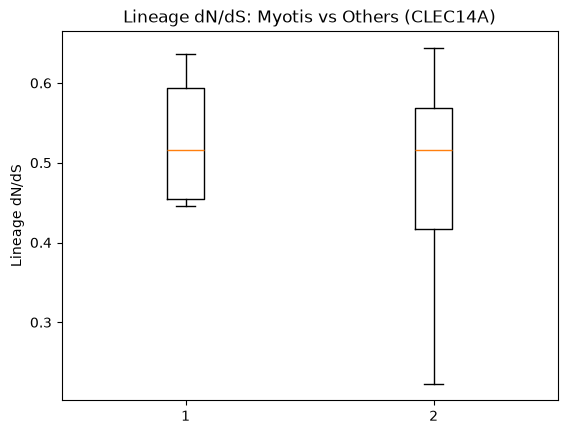

=== POLG ===
group
Myotis    0.093613
Other     0.093222
Name: lineage_dNdS, dtype: float64



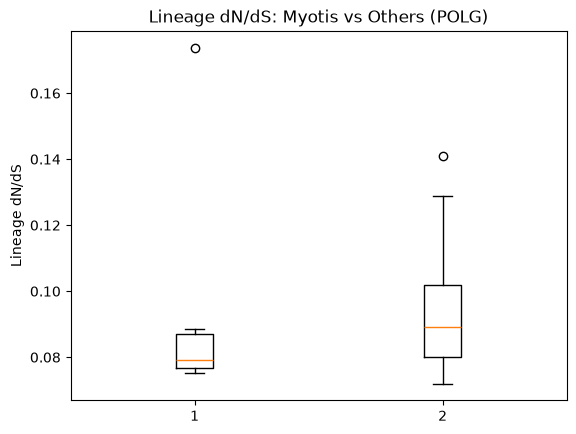

In [19]:
import matplotlib.pyplot as plt

myotis_dict = {"mb", "ml", "md", "mm", "me", "ma", "my"}

for gene in ["CLEC14A", "POLG"]:
    df = pd.read_csv(f"../hw3_mat/{gene}_dnds_LQ.csv")

    df["code"] = df["node"].str[:2].str.lower()
    df["group"] = df["code"].isin(myotis_dict).map({True: "Myotis", False: "Other"})

    print(f"=== {gene} ===")
    print(df.groupby("group")["lineage_dNdS"].mean())
    print()

    plt.figure()
    plt.boxplot(
        [df.loc[df["group"] == "Myotis", "lineage_dNdS"],
         df.loc[df["group"] == "Other",  "lineage_dNdS"]],
        label=["Myotis", "Other"],
        showmeans=False
    )
    plt.ylabel("Lineage dN/dS")
    plt.title(f"Lineage dN/dS: Myotis vs Others ({gene})")
    plt.show()

для CLEC14A у Myotis ω чуть выше, чем у остальных

для POLG разница между Myotis и Other почти ноль - никакого сигнала. 

PGLS:

In [ ]:
conda activate pgls

In [5]:
# подготовка данных для phylokrr для каждого гена
for gene in ["CLEC14A", "POLG"]:
    df = pd.read_csv(f"../hw3_mat/{gene}_dnds_LQ.csv")

    df_modified = df.drop(["node", "Species"], axis=1)
    df_modified.to_csv(f"../hw3_mat/{gene}_test_data.csv", index=False, header=False)

    species_names = df["Species"]
    species_names.to_csv(f"../hw3_mat/{gene}_species.txt", index=False, header=None)


X shape:  (30, 1)
numeric columns:  [0]
categorical columns:  []
30 names from data, 30 from tree, 30 intersect
R2 for PGLS: 0.12633146422603803
RMSE for PGLS: 1.684182793849912


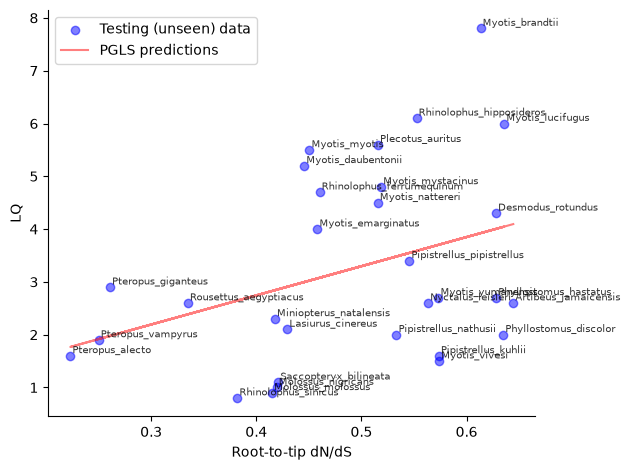

X shape:  (30, 1)
numeric columns:  [0]
categorical columns:  []
30 names from data, 30 from tree, 30 intersect
R2 for PGLS: 0.05618685353146624
RMSE for PGLS: 1.7504869993662389


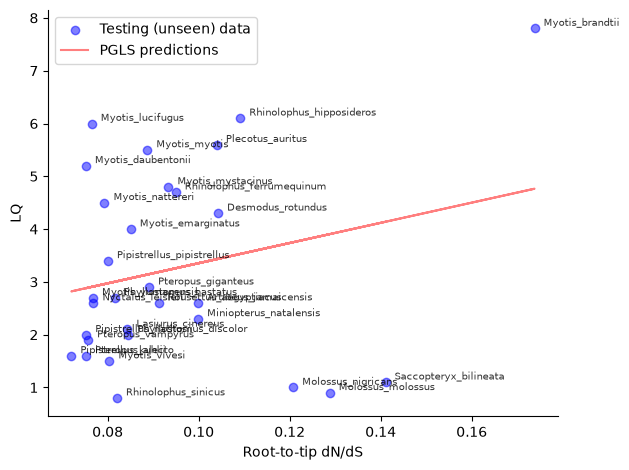

In [20]:
tree_file = "../hw3_mat/cba_comp_age_hw/pgls_tree.txt"

for gene in ["CLEC14A", "POLG"]:
    data_file = f"../hw3_mat/{gene}_test_data.csv"
    data_file_spps = f"../hw3_mat/{gene}_species.txt"

    X_uw_uc, y_uw_uc, vcv = read_data(tree_file, data_file, data_file_spps,
                                      y_col = 1, # таргет
                                      delimiter = ',', verbose = True)

    with open(data_file_spps) as f:
        species = [line.strip() for line in f]

    X_train = X_uw_uc
    y_train = y_uw_uc

    X_plot = X_train.ravel()
    y_plot = y_train.ravel()

    # PGLS
    pgls = PGLS(fit_intercept=True)
    pgls.fit(X_train, y_train)
    y_pred_pgls = pgls.predict(X_train)

    plt.figure()
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.scatter(X_plot, y_plot , color = 'blue' , alpha=0.5, label = 'Testing (unseen) data')
    plt.plot(X_plot, y_pred_pgls, color = 'red', alpha=0.5, label = 'PGLS predictions')
    dx = 0.002   #оффсет чтоб не было оверлепа
    dy = 0.05
    for i, sp in enumerate(species):
        plt.text(X_plot[i] + dx, y_plot[i] + dy, sp, fontsize=7, alpha=0.8)
    plt.xlabel('Root-to-tip dN/dS')
    plt.ylabel('LQ')
    plt.legend()
    plt.tight_layout()
    r2_pgls = pgls.score(X_train, y_train, metric='r2')
    rmse = pgls.score(X_train, y_train, metric ='rmse')
    print(f"R2 for PGLS: {r2_pgls}")
    print(f"RMSE for PGLS: {rmse}")
    plt.show()

    

для этих генов R² хуже чем у mmp25 ( для него было 0.37) - то есть линейная модель плохо объясняет данные (скорость эволюции гена (ω) не связана с продолжительностью жизни (LQ))

### **Задание 2**
Постройте multivariate PGLS модель на основе $\omega$ значений, получившихся для всех 3 генов. \
\
**Важно:** Если вам совсем не нравится phylokrr, то можете сделать это задание в R через caper.

In [22]:
import pandas as pd

dfs = {}
for gene in ["mmp25", "CLEC14A", "POLG"]:
    df = pd.read_csv(f"../hw3_mat/{gene}_dnds_LQ.csv")
    df["code"] = df["node"].str[:2].str.lower()
    dfs[gene] = df

merged = dfs["mmp25"][["code", "LQ", "lineage_dNdS"]].rename(
    columns={"lineage_dNdS": "dnds_mmp25"}
)

# добавляем dnds для остальных генов
for gene in ["CLEC14A", "POLG"]:
    merged = merged.merge(
        dfs[gene][["code", "lineage_dNdS"]].rename(
            columns={"lineage_dNdS": f"dnds_{gene}"}
        ),
        on="code",
        how="inner",
    )

species_map = dfs["mmp25"].set_index("code")["Species"].to_dict()
merged["Species"] = merged["code"].map(species_map)

multi = merged[["dnds_mmp25", "dnds_CLEC14A", "dnds_POLG", "LQ"]]
multi.to_csv("../hw3_mat/multivar_test_data.csv", index=False, header=False)

merged["Species"].to_csv("../hw3_mat/multivar_species.txt", index=False, header=None)


X shape:  (30, 3)
numeric columns:  [0, 1, 2]
categorical columns:  []
30 names from data, 30 from tree, 30 intersect


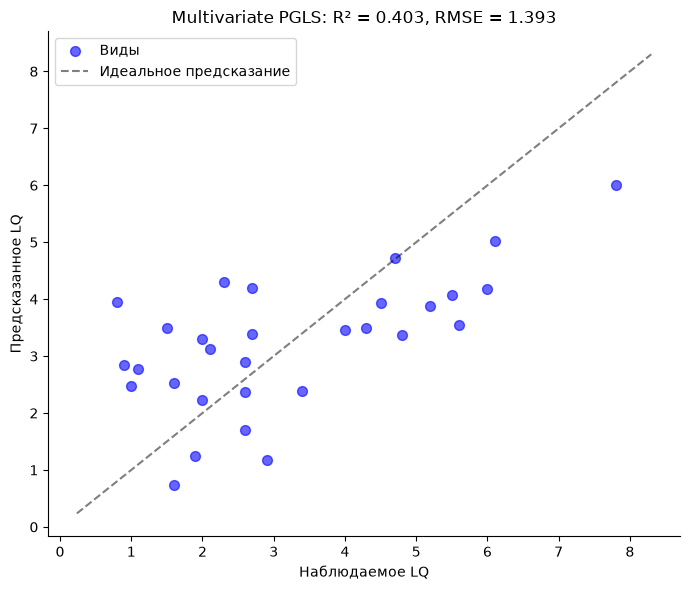

Multivariate PGLS: R² = 0.403, RMSE = 1.393


In [44]:
from phylokrr.dataio import read_data
from phylokrr.utils import PGLS

tree_file = "../hw3_mat/cba_comp_age_hw/pgls_tree.txt"

X, y, vcv = read_data(
    tree_file,
    "../hw3_mat/multivar_test_data.csv",
    "../hw3_mat/multivar_species.txt",
    y_col=3,           # LQ — 4-я колонка, индекс 3
    delimiter=",",
    verbose=True,
)

pgls_multi = PGLS(fit_intercept=True)
pgls_multi.fit(X, y)

y_pred = pgls_multi.predict(X)
r2_multi = pgls_multi.score(X, y, metric="r2")
rmse_multi = pgls_multi.score(X, y, metric="rmse")

y_true = y.ravel()
y_pred_flat = y_pred.ravel()

# R² и диагональ
plt.figure(figsize=(7, 6))
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.scatter(y_true, y_pred_flat, color="blue", alpha=0.6, s=50, label="Виды")

# диагональ y = x (идеальное предсказание)
lims = [min(y_true.min(), y_pred_flat.min()) - 0.5,
        max(y_true.max(), y_pred_flat.max()) + 0.5]
plt.plot(lims, lims, "k--", alpha=0.5, label="Идеальное предсказание")

plt.xlabel("Наблюдаемое LQ")
plt.ylabel("Предсказанное LQ")
plt.title(f"Multivariate PGLS: R² = {r2_multi:.3f}, RMSE = {rmse_multi:.3f}")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Multivariate PGLS: R² = {r2_multi:.3f}, RMSE = {rmse_multi:.3f}")

мультивариантный R² 0.4 выше лучшего одномерного (0.37 для mmp25) — значит комбинация генов лучше объясняет предполагаемую линейную зависимость

### **Задание 3**
Напишите функцию, запускающую тул MEME, анализирующий сайты под действием положительного отбора. Проанализируйте все гены им и объясните полученные результаты.

In [ ]:
for gene in mmp25 CLEC14A POLG; do
    echo "$gene"
    conda run -n hyphy hyphy meme \
        --alignment cba_comp_age_hw/${gene}_aln.fasta \
        --tree cba_comp_age_hw/${gene}_tree.nwk \
        --output ${gene}_meme_res.json > ${gene}_meme_log.txt 2>&1
done

In [42]:
import json
from statsmodels.stats.multitest import multipletests

for gene in ["mmp25", "CLEC14A", "POLG"]:
    mle = json.load(open(f"../hw3_mat/{gene}_meme_res.json"))["MLE"]
    h = [x[0] for x in mle["headers"]]
    c = mle["content"]["0"]

    i_p  = h.index("p-value")
    i_bp = h.index("&beta;<sup>+</sup>")
    i_br = h.index("# branches under selection")

    # ---------- без коррекции ----------
    raw = []
    for i, row in enumerate(c):
        if row[i_p] < 0.05 and row[i_bp] > 0 and row[i_br] >= 2:
            raw.append((i + 1, row[i_p], row[i_br]))

    print(f"=== {gene.upper()}: {len(raw)} сайтов без коррекции (p<0.05, br≥2) ===")
    for site, p, br in sorted(raw, key=lambda t: t[1]):
        print(f"  сайт {site:4d}:  p={p:.3g}   ветвей={int(br)}")

    # ---------- с FDR ----------
    pvals = [row[i_p] for row in c]
    _, qvals, _, _ = multipletests(pvals, alpha=0.1, method="fdr_bh")

    sig = []
    for i, row in enumerate(c):
        if qvals[i] < 0.1 and row[i_bp] > 0 and row[i_br] >= 2:
            sig.append((i + 1, row[i_p], qvals[i], row[i_br]))

    print(f"--- {gene.upper()}: {len(sig)} сайтов после FDR (q<0.1, br≥2) ---")
    for site, p, q, br in sorted(sig, key=lambda t: t[2]):
        print(f"  сайт {site:4d}:  p={p:.3g}   q={q:.3g}   ветвей={int(br)}")
    print()

=== MMP25: 3 сайтов без коррекции (p<0.05, br≥2) ===
  сайт  373:  p=5.56e-05   ветвей=3
  сайт  408:  p=0.00443   ветвей=4
  сайт  492:  p=0.0219   ветвей=2
--- MMP25: 1 сайтов после FDR (q<0.1, br≥2) ---
  сайт  373:  p=5.56e-05   q=0.0276   ветвей=3

=== CLEC14A: 3 сайтов без коррекции (p<0.05, br≥2) ===
  сайт   40:  p=0.015   ветвей=3
  сайт   95:  p=0.0158   ветвей=2
  сайт  244:  p=0.0174   ветвей=3
--- CLEC14A: 0 сайтов после FDR (q<0.1, br≥2) ---

=== POLG: 4 сайтов без коррекции (p<0.05, br≥2) ===
  сайт  516:  p=0.00929   ветвей=3
  сайт   93:  p=0.0252   ветвей=2
  сайт  243:  p=0.036   ветвей=2
  сайт  194:  p=0.0468   ветвей=2
--- POLG: 0 сайтов после FDR (q<0.1, br≥2) ---



итого сайт 373 для MMP25 — единственный реальный кандидат на роль адаптации к долголетию.. Это согласуется с результатами BUSTED (значимый отбор в гене) и aBSREL (2 ветви под отбором)

для CLEC14A - пограничный случай. ω у Myotis выше, чем у остальных, и разница хоть и небольшая, видимо это различие не дотянуло до значимого положительного отбора

для POLG вообще не сигнлаа. ω у Myotis и остальных практически идентичны - очищающий отбор. POLG — эволюционно консервативный ген, не подходящий для поиска адаптаций к долголетию.